In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
import numpy as np

## Load Data

In [3]:
# Load data
data_folder = r'C:\Users\esteb\OneDrive - Universidad de los andes\Documentos\ANDES\Noveno Semestre\PA-RSPPs\PA-Experiments\output_new'

#Chicago Sketch
CS_full_experiment = pd.read_csv(os.path.join(data_folder, 'CS_full_experiment.csv'))
CS_bounds_experiment = pd.read_csv(os.path.join(data_folder, 'CS_bounds_experiment.csv'))
CS_feasibility_experiment = pd.read_csv(os.path.join(data_folder, 'CS_feasibility_experiment.csv'))
CS_full_pruning = pd.read_csv(os.path.join(data_folder, 'CS_full_pruning.csv'))

# Chicago Regional
CR_full_experiment = pd.read_csv(os.path.join(data_folder, 'CR_full_experiment.csv'))
CR_bounds_experiment = pd.read_csv(os.path.join(data_folder, 'CR_bounds_experiment.csv'))
CR_feasibility_experiment = pd.read_csv(os.path.join(data_folder, 'CR_feasibility_experiment.csv'))
CR_full_pruning = pd.read_csv(os.path.join(data_folder, 'CR_full_pruning.csv'))
CR_bounds_timeout = pd.read_csv(os.path.join(data_folder, 'CR_timeout_experiment.csv'))

# Sydney
SY_full_experiment = pd.read_csv(os.path.join(data_folder, 'SY_full_experiment.csv'))
SY_bounds_experiment = pd.read_csv(os.path.join(data_folder, 'SY_bounds_experiment.csv'))
SY_feasibility_experiment = pd.read_csv(os.path.join(data_folder, 'SY_feasibility_experiment.csv'))
SY_full_pruning = pd.read_csv(os.path.join(data_folder, 'SY_full_pruning.csv'))
SY_bounds_timeout = pd.read_csv(os.path.join(data_folder, 'SY_timeout_experiment.csv'))

# Define colors
pastel_green = "#79b385"  # Darker shade of pastel green
pastel_blue = "#6a9db5"   # Darker shade of pastel blue
pastel_orange = "#d6a65b"  # Darker shade of pastel orange
pastel_red = "#d66a5b"    # Darker shade of pastel red

## SARP

Mean:  6.77e-03---- 1.89e-01---- 3.66e-01----
Median:  6.06e-03---- 1.71e-01---- 3.41e-01----
Std:  3.96e-03---- 4.63e-02---- 6.29e-02----


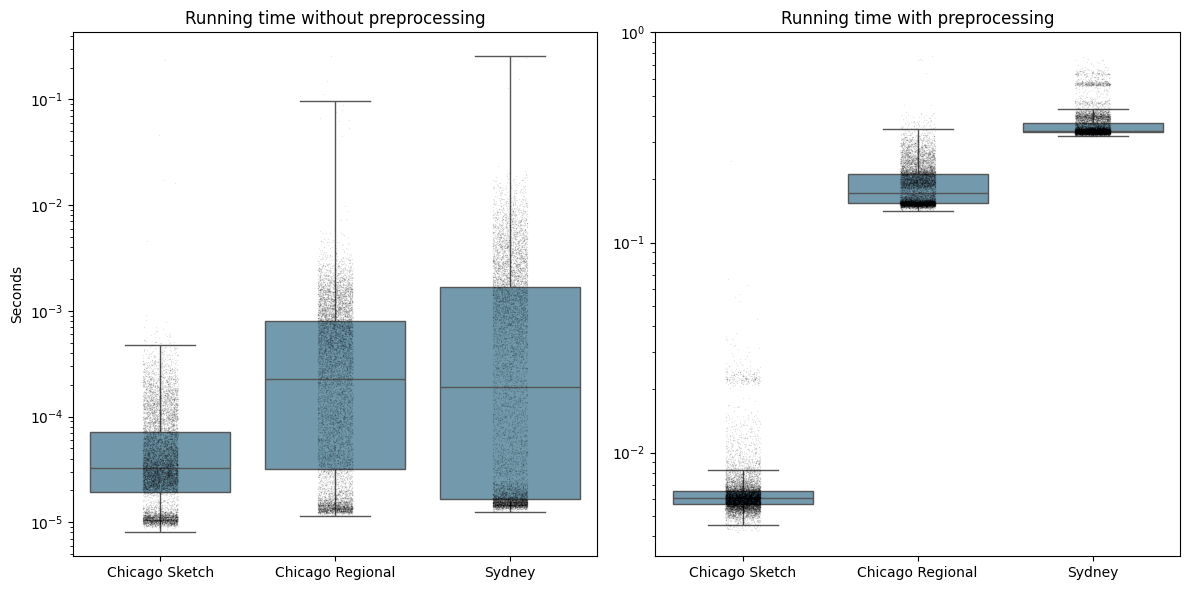

In [4]:
# Extract values
CS_raw = CS_full_experiment["elapsed_time"].values
CR_raw = CR_full_experiment["elapsed_time"].values
SY_raw = SY_full_experiment["elapsed_time"].values

#check that there was not timeout
assert np.all(CS_full_experiment["timeout"] == False), "CS experiment timed out"
assert np.all(CR_full_experiment["timeout"] == False), "CR experiment timed out"
assert np.all(SY_full_experiment["timeout"] == False), "SY experiment timed out"

CS_prep = CS_full_experiment["preprocessing_time"].values + CS_raw
CR_prep = CR_full_experiment["preprocessing_time"].values + CR_raw
SY_prep = SY_full_experiment["preprocessing_time"].values + SY_raw
print("Mean: ", 
      f"{CS_prep.mean():.2e}----", 
      f"{CR_prep.mean():.2e}----", 
      f"{SY_prep.mean():.2e}----")
print("Median: ",
      f"{np.median(CS_prep):.2e}----", 
      f"{np.median(CR_prep):.2e}----", 
      f"{np.median(SY_prep):.2e}----")
print("Std: ",
        f"{CS_prep.std():.2e}----", 
        f"{CR_prep.std():.2e}----", 
        f"{SY_prep.std():.2e}----")

# Create DataFrames
df_raw = pd.DataFrame({
    "Time": list(CS_raw) + list(CR_raw) + list(SY_raw),
    "Network": ["Chicago Sketch"] * len(CS_raw) + ["Chicago Regional"] * len(CR_raw) + ["Sydney"] * len(SY_raw)
})

df_prep = pd.DataFrame({
    "Time": list(CS_prep) + list(CR_prep) + list(SY_prep),
    "Network": ["Chicago Sketch"] * len(CS_prep) + ["Chicago Regional"] * len(CR_prep) + ["Sydney"] * len(SY_prep)
})

# Subplots with independent y-axes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))  # No sharey

# Raw times plot
sns.boxplot(data=df_raw, x="Network", y="Time", log_scale=True,
            showfliers=False, color=pastel_blue, ax=axes[0])
sns.stripplot(data=df_raw, x="Network", y="Time", color='black',
              alpha=0.1, size=1, jitter=True, log_scale=True, ax=axes[0])
axes[0].set_title("Running time without preprocessing")
axes[0].set_ylabel("Seconds", fontsize=10)

# Prepended times plot
sns.boxplot(data=df_prep, x="Network", y="Time", log_scale=True,
            showfliers=False, color=pastel_blue, ax=axes[1])
sns.stripplot(data=df_prep, x="Network", y="Time", color='black',
              alpha=0.1, size=1, jitter=True, log_scale=True, ax=axes[1])
axes[1].set_title("Running time with preprocessing")
axes[1].set_ylabel("")
axes[1].set_xlabel("")
axes[0].set_xlabel("")

plt.tight_layout()
plt.show()


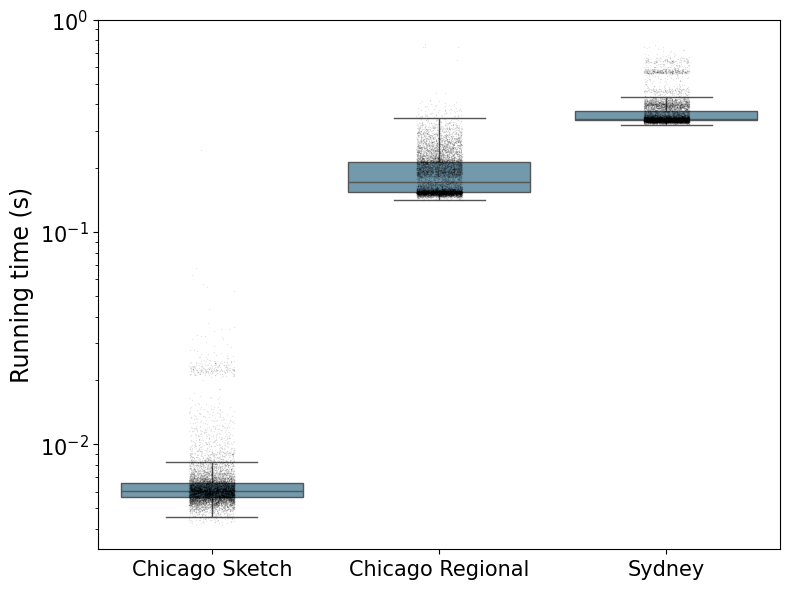

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6)) # Adjusted figsize for single plot

# Prepended times plot on the single axis
sns.boxplot(data=df_prep, x="Network", y="Time", log_scale=True,
            showfliers=False, color=pastel_blue, ax=ax)
sns.stripplot(data=df_prep, x="Network", y="Time", color='black',
              alpha=0.1, size=1, jitter=True, log_scale=True, ax=ax)

# Set title and labels for the single plot
ax.set_ylabel("Running time (s)", fontsize=17)
ax.set_xlabel("", fontsize=15)
ax.tick_params(axis='both', which='major', labelsize=15)

plt.tight_layout()
plt.show()

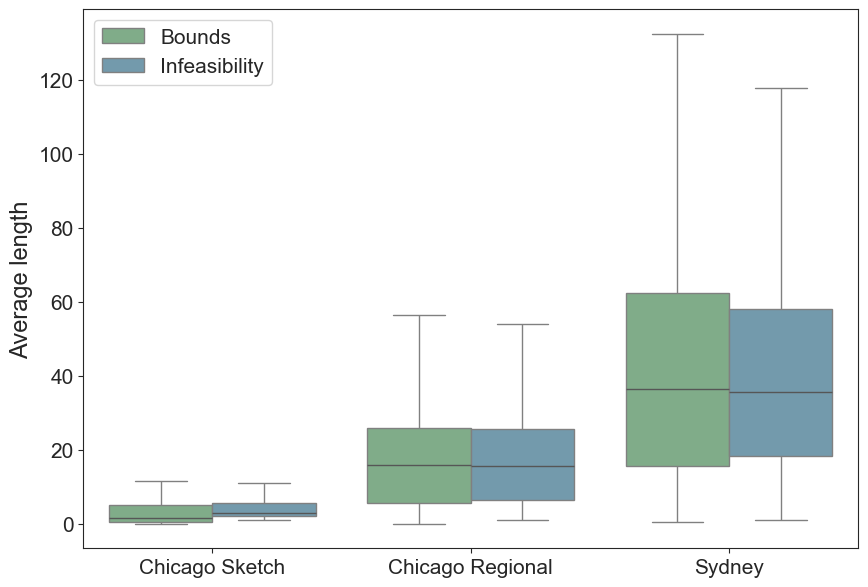

In [6]:
CS_bounds = CS_full_pruning['length_pruned_by_bounds'].dropna()
CR_bounds = CR_full_pruning['length_pruned_by_bounds'].dropna()
SY_bounds = SY_full_pruning['length_pruned_by_bounds'].dropna()

CS_feasibility = CS_full_pruning['length_pruned_by_feasibility'].dropna()
CR_feasibility = CR_full_pruning['length_pruned_by_feasibility'].dropna()
SY_feasibility = SY_full_pruning['length_pruned_by_feasibility'].dropna()

dataframes = [
    pd.DataFrame({'Average length': CS_bounds, 'Network': 'Chicago Sketch', 'Pruning Strategy': 'Bounds'}),
    pd.DataFrame({'Average length': CR_bounds, 'Network': 'Chicago Regional', 'Pruning Strategy': 'Bounds'}),
    pd.DataFrame({'Average length': SY_bounds, 'Network': 'Sydney', 'Pruning Strategy': 'Bounds'}),
    pd.DataFrame({'Average length': CS_feasibility, 'Network': 'Chicago Sketch', 'Pruning Strategy': 'Infeasibility'}),
    pd.DataFrame({'Average length': CR_feasibility, 'Network': 'Chicago Regional', 'Pruning Strategy': 'Infeasibility'}),
    pd.DataFrame({'Average length': SY_feasibility, 'Network': 'Sydney', 'Pruning Strategy': 'Infeasibility'})
]

# Combine all DataFrames into a single one
df_long = pd.concat(dataframes, ignore_index=True)

sns.set_style("ticks")
plt.figure(figsize=(10, 7)) # Set the figure size

# Define custom colors to match the image
custom_palette = {
    'Bounds': pastel_green,
    'Infeasibility': pastel_blue
}

# Generate the box plot
ax = sns.boxplot(
    data=df_long,
    x='Network',
    y='Average length',
    hue='Pruning Strategy',
    palette=custom_palette,
    boxprops={'edgecolor': 'gray'},
    whiskerprops={'color': 'gray'},
    capprops={'color': 'gray'},
    showfliers=False
)
# do not show outliers
ax.legend(loc='upper left', fontsize=15)
ax.set_ylabel("Average length", fontsize=17)
ax.set_xlabel("", fontsize=15)
ax.tick_params(axis='both', which='major', labelsize=15)

In [7]:
print(f"Chicago Sketch. Bounds: {CS_bounds.mean()}, Infeasibility: {CS_feasibility.mean()}")
print(f"Chicago Regional. Bounds: {CR_bounds.mean()}, Infeasibility: {CR_feasibility.mean()}")
print(f"Sydney. Bounds: {SY_bounds.mean()}, Infeasibility: {SY_feasibility.mean()}")


Chicago Sketch. Bounds: 3.1188480978983772, Infeasibility: 4.123028640001769
Chicago Regional. Bounds: 17.08996554275722, Infeasibility: 17.280611847175972
Sydney. Bounds: 42.458758475152585, Infeasibility: 40.895414425843036


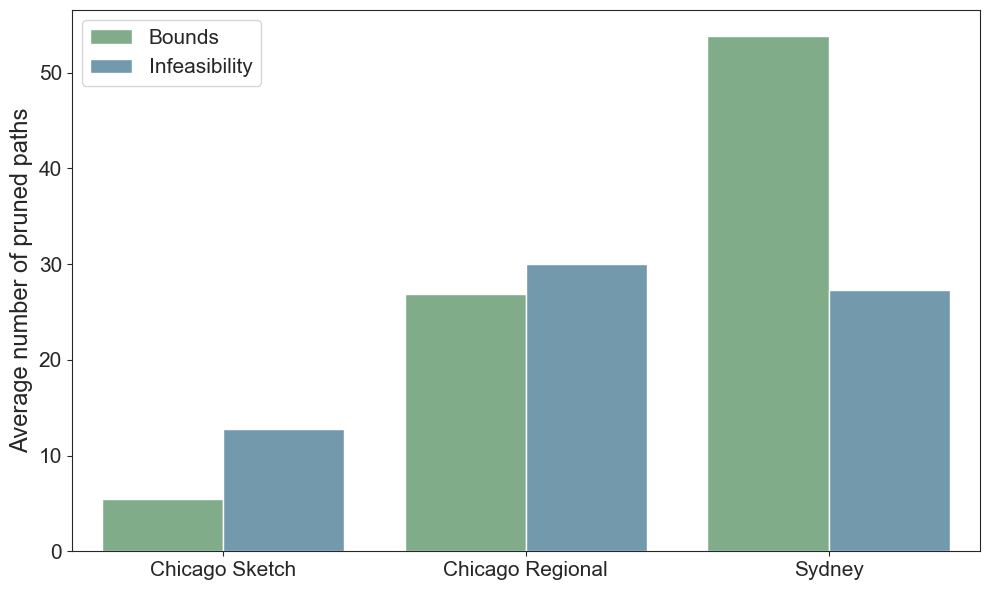

In [8]:
data = {
    'Network': ['Chicago Sketch', 'Chicago Sketch', 'Chicago Regional', 'Chicago Regional', 'Sydney', 'Sydney'],
    'Metric': ['Bounds', 'Infeasibility', 'Bounds', 'Infeasibility', 'Bounds', 'Infeasibility'],
    'Value': [
        CS_full_experiment['pruned_by_bounds'].mean(),
        CS_full_experiment['pruned_by_feasibility'].mean(),
        CR_full_experiment['pruned_by_bounds'].mean(),
        CR_full_experiment['pruned_by_feasibility'].mean(),
        SY_full_experiment['pruned_by_bounds'].mean(),
        SY_full_experiment['pruned_by_feasibility'].mean()
    ]
}

df = pd.DataFrame(data)

color_palette = {
    'Bounds': pastel_green,
    'Infeasibility': pastel_blue
}

plt.figure(figsize=(10, 6)) # Adjust figure size as needed
sns.barplot(x='Network', y='Value', hue='Metric', data=df, palette=color_palette)
plt.ylabel('Average number of pruned paths', fontsize=17)
plt.xlabel('', fontsize=10)
plt.legend(loc='upper left', fontsize=15)
plt.tick_params(axis='both', which='major', labelsize=15)
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

In [9]:
print(CS_full_experiment['pruned_by_bounds'].mean(),
        CS_full_experiment['pruned_by_feasibility'].mean(),
        CR_full_experiment['pruned_by_bounds'].mean(),
        CR_full_experiment['pruned_by_feasibility'].mean(),
        SY_full_experiment['pruned_by_bounds'].mean(),
        SY_full_experiment['pruned_by_feasibility'].mean())

5.4413 12.7755 26.8588 29.9938 53.838090452261305 27.242311557788945


In [10]:
CS_bounds_percent = (CS_full_experiment['pruned_by_bounds'] / (CS_full_experiment['pruned_by_bounds'] + CS_full_experiment['pruned_by_feasibility'])).mean() * 100
CS_inf_percent = (CS_full_experiment['pruned_by_feasibility'] / (CS_full_experiment['pruned_by_bounds'] + CS_full_experiment['pruned_by_feasibility'])).mean() * 100

CR_bounds_percent = (CR_full_experiment['pruned_by_bounds'] / (CR_full_experiment['pruned_by_bounds'] + CR_full_experiment['pruned_by_feasibility'])).mean() * 100
CR_inf_percent = (CR_full_experiment['pruned_by_feasibility'] / (CR_full_experiment['pruned_by_bounds'] + CR_full_experiment['pruned_by_feasibility'])).mean() * 100

SY_bounds_percent = (SY_full_experiment['pruned_by_bounds'] / (SY_full_experiment['pruned_by_bounds'] + SY_full_experiment['pruned_by_feasibility'])).mean() * 100
SY_inf_percent = (SY_full_experiment['pruned_by_feasibility'] / (SY_full_experiment['pruned_by_bounds'] + SY_full_experiment['pruned_by_feasibility'])).mean() * 100

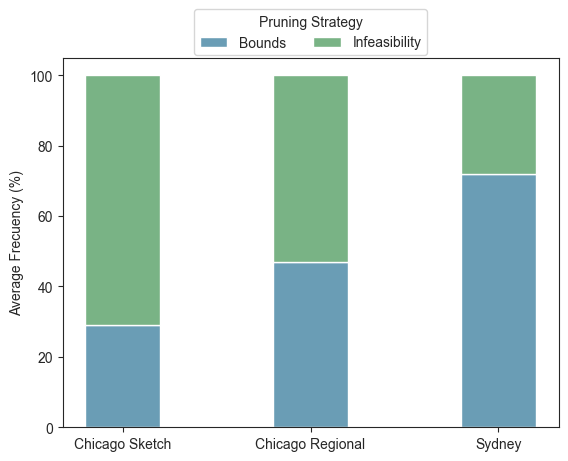

Chicago Sketch
Bounds:  29.172718900726935
Infeasibility:  70.82728109927308
Chicago Regional
Bounds:  46.84611017393803
Infeasibility:  53.15388982606196
Sydney
Bounds:  71.82376525469091
Infeasibility:  28.17623474530909


In [11]:
fig, ax = plt.subplots()

sns.barplot()

bar_width = 0.4

ax.bar("Chicago Sketch", CS_bounds_percent, label="Bounds", color=pastel_blue, width=bar_width)
ax.bar("Chicago Sketch", CS_inf_percent, bottom=CS_bounds_percent, label="Infeasibility", color=pastel_green, width=bar_width)

ax.bar("Chicago Regional", CR_bounds_percent, color=pastel_blue, width=bar_width)
ax.bar("Chicago Regional", CR_inf_percent, bottom=CR_bounds_percent, color=pastel_green, width=bar_width)

ax.bar("Sydney", SY_bounds_percent, color=pastel_blue, width=bar_width)
ax.bar("Sydney", SY_inf_percent, bottom=SY_bounds_percent, color=pastel_green, width=bar_width)

handles, labels = ax.get_legend_handles_labels()
unique_labels = dict(zip(labels, handles))  # Use a dictionary to keep unique labels
ax.legend(unique_labels.values(), unique_labels.keys(), title="Pruning Strategy", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.15))

plt.ylabel("Average Frecuency (%)")
plt.show()

#Print the values for each bar graph
print("Chicago Sketch")
print("Bounds: ", CS_bounds_percent)
print("Infeasibility: ", CS_inf_percent)
print("Chicago Regional")
print("Bounds: ", CR_bounds_percent)
print("Infeasibility: ", CR_inf_percent)
print("Sydney")
print("Bounds: ", SY_bounds_percent)
print("Infeasibility: ", SY_inf_percent)


In [12]:
#remove rows that timeout == true
CS_full_experiment = CS_full_experiment[CS_full_experiment['timeout'] == False]
CR_full_experiment = CR_full_experiment[CR_full_experiment['timeout'] == False]
SY_full_experiment = SY_full_experiment[SY_full_experiment['timeout'] == False]

CS_bounds_experiment = CS_bounds_experiment[CS_bounds_experiment['timeout'] == False]
CR_bounds_experiment = CR_bounds_experiment[CR_bounds_experiment['timeout'] == False]
SY_bounds_experiment = SY_bounds_experiment[SY_bounds_experiment['timeout'] == False]

CS_feasibility_experiment = CS_feasibility_experiment[CS_feasibility_experiment['timeout'] == False]
CR_feasibility_experiment = CR_feasibility_experiment[CR_feasibility_experiment['timeout'] == False]
SY_feasibility_experiment = SY_feasibility_experiment[SY_feasibility_experiment['timeout'] == False]

print(f"{CS_full_experiment['elapsed_time'].mean():.2e}",
      f"{CS_full_experiment['elapsed_time'].std():.2e}",
      f"{CR_full_experiment['elapsed_time'].mean():.2e}",
      f"{CR_full_experiment['elapsed_time'].std():.2e}",
      f"{SY_full_experiment['elapsed_time'].mean():.2e}",
      f"{SY_full_experiment['elapsed_time'].std():.2e}")

print(f"{CS_bounds_experiment['elapsed_time'].mean():.2e}",
      f"{CS_bounds_experiment['elapsed_time'].std():.2e}",
      f"{CR_bounds_experiment['elapsed_time'].mean():.2e}",
      f"{CR_bounds_experiment['elapsed_time'].std():.2e}",
      f"{SY_bounds_experiment['elapsed_time'].mean():.2e}",
      f"{SY_bounds_experiment['elapsed_time'].std():.2e}")

print(f"{CS_feasibility_experiment['elapsed_time'].mean():.2e}",
      f"{CS_feasibility_experiment['elapsed_time'].std():.2e}",
      f"{CR_feasibility_experiment['elapsed_time'].mean():.2e}",
      f"{CR_feasibility_experiment['elapsed_time'].std():.2e}",
      f"{SY_feasibility_experiment['elapsed_time'].mean():.2e}",
      f"{SY_feasibility_experiment['elapsed_time'].std():.2e}")


9.29e-05 2.43e-03 6.35e-04 3.88e-03 1.45e-03 5.30e-03
1.27e-04 3.09e-04 1.54e-02 1.64e-01 9.18e-03 1.33e-01
1.51e-04 3.44e-04 1.16e-03 2.77e-03 5.85e-03 8.73e-03


Chicago Regional
timeout
False    40
True     12
Name: count, dtype: int64
count     40.000000
mean      87.673183
std      123.627318
min        8.670800
25%       16.796215
50%       33.161309
75%       88.582380
max      579.742774
Name: elapsed_time, dtype: float64
--------------
Sydney
timeout
False    34
True      2
Name: count, dtype: int64
count     34.000000
mean      47.817624
std       49.891214
min        6.944187
25%       15.832806
50%       34.441104
75%       63.113708
max      264.473724
Name: elapsed_time, dtype: float64


C:\Users\esteb\AppData\Local\Temp\ipykernel_63296\2322711897.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  CR_no_timeout['Network'] = "Chicago Regional"
C:\Users\esteb\AppData\Local\Temp\ipykernel_63296\2322711897.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  CR_no_timeout["Time"] = CR_no_timeout["elapsed_time"]
C:\Users\esteb\AppData\Local\Temp\ipykernel_63296\2322711897.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer

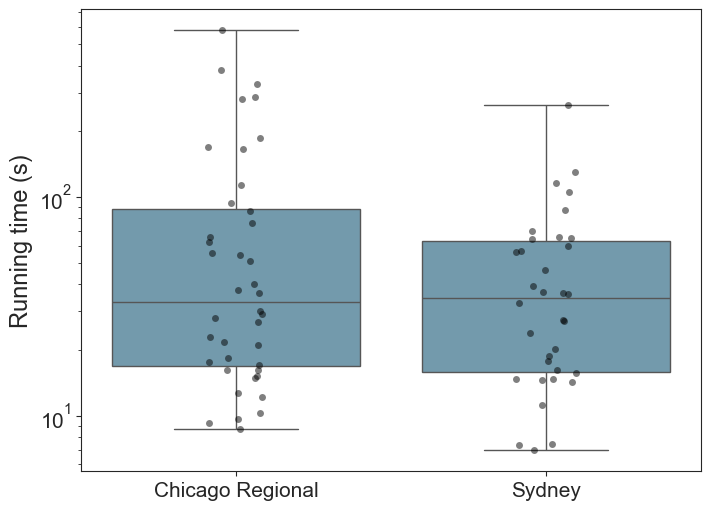

In [13]:
print("Chicago Regional")
print(CR_bounds_timeout['timeout'].value_counts())
CR_no_timeout = CR_bounds_timeout[CR_bounds_timeout['timeout'] == False]
print(CR_no_timeout['elapsed_time'].describe())
CR_no_timeout['Network'] = "Chicago Regional" 
CR_no_timeout["Time"] = CR_no_timeout["elapsed_time"]

print("--------------")
print("Sydney")
print(SY_bounds_timeout['timeout'].value_counts())
SY_no_timeout = SY_bounds_timeout[SY_bounds_timeout['timeout'] == False]
print(SY_no_timeout['elapsed_time'].describe())
SY_no_timeout['Network'] = "Sydney"
SY_no_timeout["Time"] = SY_no_timeout["elapsed_time"]
merged = pd.concat([CR_no_timeout, SY_no_timeout], axis=0)


fig, ax = plt.subplots(1, 1, figsize=(8, 6)) # Adjusted figsize for single plot

# Prepended times plot on the single axis
sns.boxplot(data=merged, x="Network", y="Time", log_scale=True,
            showfliers=False, color=pastel_blue, ax=ax)
sns.stripplot(data=merged, x="Network", y="Time", color='black',
              alpha=0.5, size=5, jitter=True, log_scale=True, ax=ax)

# Set title and labels for the single plot
ax.set_ylabel("Running time (s)", fontsize=17)
ax.set_xlabel("", fontsize=10)
ax.tick_params(axis='both', which='major', labelsize=15)


## SDRSPP

In [14]:
## Load data
data_folder = r'C:\Users\esteb\OneDrive - Universidad de los andes\Documentos\ANDES\Noveno Semestre\PA-RSPPs\PA-Experiments\output_new'

def load_csvs_with_substring(directory, substring):
    dataframes = []
    filenames = []

    for file in os.listdir(directory):
        if file.endswith(".csv") and substring in file:
            full_path = os.path.join(directory, file)
            df = pd.read_csv(full_path)
            dataframes.append(df)
            filenames.append(file)

    return dataframes, filenames

time_sdrspp, _ = load_csvs_with_substring(data_folder, 'time_sdrsp')
nondominated_sdrspp, _ = load_csvs_with_substring(data_folder, 'nondominated_sdrsp')

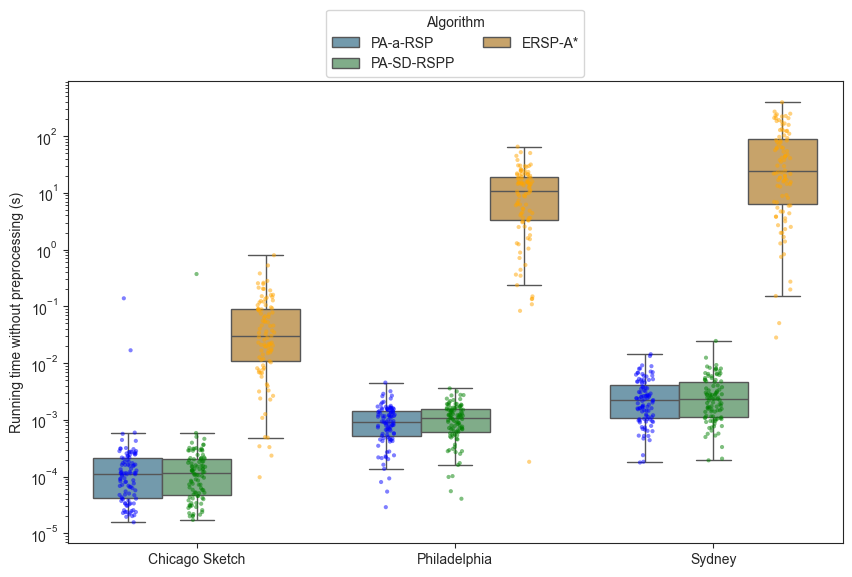

Mean Running Time for Each Algorithm by Network:
          Network   Algorithm      Time
0  Chicago Sketch     ERSP-A*  7.38e-02
1  Chicago Sketch  PA-SD-RSPP  3.85e-03
2  Chicago Sketch    PA-a-RSP  1.69e-03
3    Philadelphia     ERSP-A*  1.33e+01
4    Philadelphia  PA-SD-RSPP  1.15e-03
5    Philadelphia    PA-a-RSP  1.06e-03
6          Sydney     ERSP-A*  6.39e+01
7          Sydney  PA-SD-RSPP  3.27e-03
8          Sydney    PA-a-RSP  2.99e-03


In [15]:
# remove certain columns of the list
time_sdrspp_noprep = [df.drop(columns=[col for col in df.columns if 'pt' in col]) for df in time_sdrspp]

melted_data_list = [
    pd.melt(df, var_name="Network", value_name="Time")
    for df in time_sdrspp_noprep
]
melted_data = pd.concat(melted_data_list, ignore_index=True)
melted_data.dropna(inplace=True)

melted_data["Algorithm"] = melted_data["Network"].apply(
    lambda x: "ERSP-A*" if "ERSPA" in x else ("PA-SD-RSPP" if "dominance" in x else "PA-a-RSP")
)
melted_data["Network"] = melted_data["Network"].replace({
    "CS_t": "Chicago Sketch",
    "CS_t_ERSPA": "Chicago Sketch",
    "CS_t_dominance": "Chicago Sketch",
    "PH_t": "Philadelphia",
    "PH_t_ERSPA": "Philadelphia",
    "PH_t_dominance": "Philadelphia",
    "SY_t": "Sydney",
    "SY_t_ERSPA": "Sydney", 
    "SY_t_dominance": "Sydney",
})

fig, ax = plt.subplots(figsize=(10, 6))


boxplot = sns.boxplot(
    data=melted_data,
    x="Network",
    y="Time",
    hue="Algorithm",
    palette=[pastel_blue, pastel_green, pastel_orange],
    showfliers=False,
    ax=ax,
    log_scale=True)

# Adding strip plot for individual data points
sns.stripplot(
    data=melted_data,
    x="Network",
    y="Time",
    hue="Algorithm",
    palette=["blue", "green", "orange"],
    dodge=True,
    alpha=0.5,
    size=3,
    jitter=True,
    log_scale=True,
    ax=ax,
    legend=False
)

ax.legend(title="Algorithm", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.17))
ax.set_xlabel('')
boxplot.set_ylabel("Running time without preprocessing (s)", fontsize=10)
plt.show()

mean_values = melted_data.groupby(["Network", "Algorithm"])["Time"].mean().reset_index()
mean_values["Time"] = mean_values["Time"].apply(lambda x: "{:.2e}".format(x))
print("Mean Running Time for Each Algorithm by Network:")
print(mean_values)

In [16]:
for df in time_sdrspp:
    pt_cols = [col for col in df.columns if '_pt' in col]
    df = df[pt_cols]
    print(df.describe())

            CS_pt  CS_pt_dominance  CS_pt_ERSPA
count  100.000000       100.000000   100.000000
mean     0.005067         0.004871     0.000012
std      0.002276         0.002985     0.000003
min      0.003503         0.003456     0.000010
25%      0.004323         0.004040     0.000011
50%      0.004656         0.004328     0.000011
75%      0.004955         0.004673     0.000012
max      0.020333         0.028745     0.000039
            PH_pt  PH_pt_dominance  PH_pt_ERSPA
count  100.000000       100.000000   100.000000
mean     0.111636         0.113057     0.000215
std      0.032579         0.032240     0.000071
min      0.096357         0.096740     0.000162
25%      0.099582         0.099957     0.000187
50%      0.101640         0.102062     0.000196
75%      0.110594         0.108719     0.000219
max      0.377920         0.355895     0.000829
           SY_pt  SY_pt_dominance  SY_pt_ERSPA
count  99.000000        99.000000    99.000000
mean    0.252603         0.265660     0.00

In [17]:
time_sdrspp_summed = []

for df in time_sdrspp:
    pt_cols = [col for col in df.columns if '_pt' in col]
    t_cols = [col for col in df.columns if '_t' in col]

    # Normalize to base names (strip _pt or _t)
    pt_keys = {col.replace('_pt', ''): col for col in pt_cols}
    t_keys = {col.replace('_t', ''): col for col in t_cols}

    # Find common base names
    common_keys = set(pt_keys).intersection(t_keys)

    # Create new DataFrame with only the summed columns
    new_df = pd.DataFrame()
    for key in common_keys:
        new_df[key] = df[pt_keys[key]] + df[t_keys[key]]
    
    time_sdrspp_summed.append(new_df)

In [18]:
for i, df in enumerate(time_sdrspp_summed):
    print(df.describe())

         CS_ERSPA          CS  CS_dominance
count  100.000000  100.000000    100.000000
mean     0.073793    0.006756      0.008726
std      0.114125    0.014491      0.037245
min      0.000111    0.003522      0.003486
25%      0.010725    0.004458      0.004150
50%      0.029506    0.004790      0.004489
75%      0.091208    0.005115      0.004817
max      0.796746    0.147514      0.376247
               PH    PH_ERSPA  PH_dominance
count  100.000000  100.000000    100.000000
mean     0.112695   13.258132      0.114209
std      0.032768   12.458551      0.032443
min      0.097401    0.000370      0.097009
25%      0.100260    3.310574      0.100658
50%      0.102253   10.886236      0.103302
75%      0.111208   19.402797      0.110016
max      0.379687   65.211863      0.357393
       SY_dominance    SY_ERSPA         SY
count     99.000000   99.000000  99.000000
mean       0.268934   63.915337   0.255597
std        0.103143   79.365143   0.077248
min        0.223504    0.028560   0.

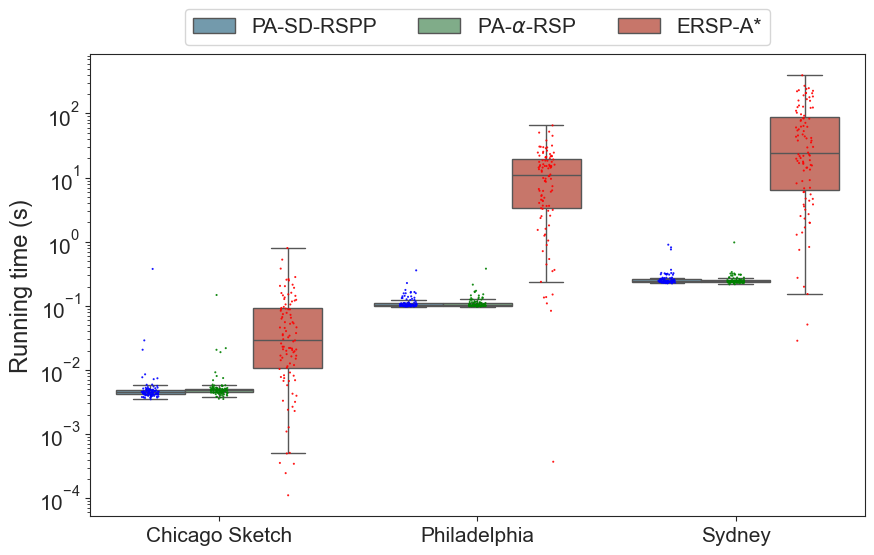

Mean Running Time for Each Algorithm by Network:
          Network        Algorithm      Time
0  Chicago Sketch          ERSP-A*  7.38e-02
1  Chicago Sketch  PA-$\alpha$-RSP  6.76e-03
2  Chicago Sketch       PA-SD-RSPP  8.73e-03
3    Philadelphia          ERSP-A*  1.33e+01
4    Philadelphia  PA-$\alpha$-RSP  1.13e-01
5    Philadelphia       PA-SD-RSPP  1.14e-01
6          Sydney          ERSP-A*  6.39e+01
7          Sydney  PA-$\alpha$-RSP  2.56e-01
8          Sydney       PA-SD-RSPP  2.69e-01


In [19]:
melted_data_list = [
    pd.melt(df, var_name="Network", value_name="Time")
    for df in time_sdrspp_summed
]

melted_data = pd.concat(melted_data_list, ignore_index=True)
melted_data.dropna(inplace=True)

melted_data["Algorithm"] = melted_data["Network"].apply(
    lambda x: "ERSP-A*" if "ERSPA" in x else ("PA-SD-RSPP" if "dominance" in x else "PA-$\\alpha$-RSP")
)
melted_data["Network"] = melted_data["Network"].replace({
    "CS": "Chicago Sketch",
    "CS_ERSPA": "Chicago Sketch",
    "CS_dominance": "Chicago Sketch",
    "PH": "Philadelphia",
    "PH_ERSPA": "Philadelphia",
    "PH_dominance": "Philadelphia",
    "SY": "Sydney",
    "SY_ERSPA": "Sydney", 
    "SY_dominance": "Sydney",
})

fig, ax = plt.subplots(figsize=(10, 6))

algorithm_order = ["PA-SD-RSPP", "PA-$\\alpha$-RSP", "ERSP-A*"]

boxplot = sns.boxplot(
    data=melted_data,
    x="Network",
    y="Time",
    hue="Algorithm",
    palette=[pastel_blue, pastel_green, pastel_red],
    showfliers=False,
    hue_order=algorithm_order,
    ax=ax,
    log_scale=True
)

# Adding strip plot for individual data points
sns.stripplot(
    data=melted_data,
    x="Network",
    y="Time",
    hue="Algorithm",
    palette=["blue", "green", "red"],
    hue_order=algorithm_order,
    dodge=True,
    alpha=0.9,
    size=1.5,
    jitter=True,
    log_scale=True,
    ax=ax,
    legend=False
)

ax.legend(title="", loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.12), fontsize=15)
ax.set_xlabel('')
boxplot.set_ylabel("Running time (s)", fontsize=17)
ax.tick_params(axis='both', which='major', labelsize=15)
plt.show()

mean_values = melted_data.groupby(["Network", "Algorithm"])["Time"].mean().reset_index()
mean_values["Time"] = mean_values["Time"].apply(lambda x: "{:.2e}".format(x))
print("Mean Running Time for Each Algorithm by Network:")
print(mean_values)

In [20]:
print(nondominated_sdrspp[0].mean())
print(nondominated_sdrspp[1].mean())
print(nondominated_sdrspp[2].mean())

CS_n                0.27
CS_n_dominance      0.27
CS_n_ERSPA        302.44
dtype: float64
PH_n                 0.71
PH_n_dominance       0.71
PH_n_ERSPA        1364.18
dtype: float64
SY_n                0.888889
SY_n_dominance      0.888889
SY_n_ERSPA        963.343434
dtype: float64


c:\Users\esteb\.pyenv\pyenv-win\versions\3.10.11\lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
c:\Users\esteb\.pyenv\pyenv-win\versions\3.10.11\lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


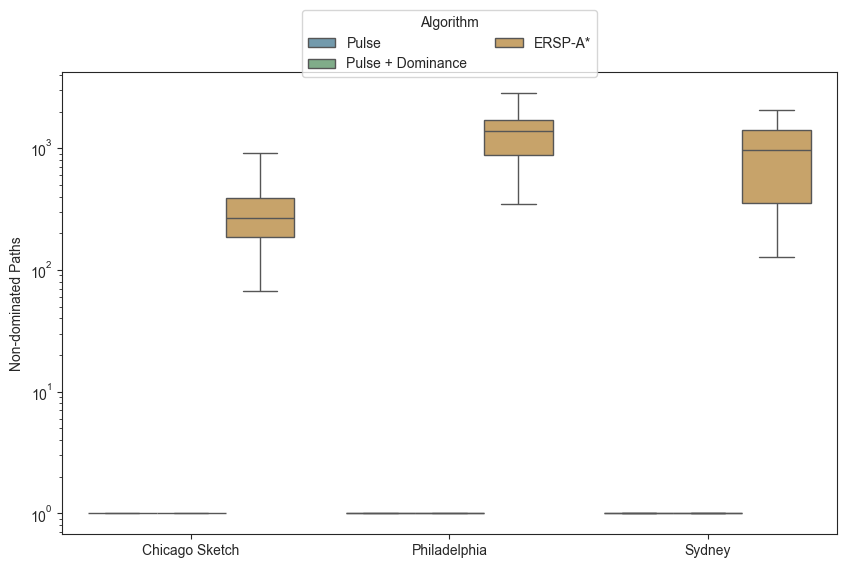

Mean Non-Dominated Paths for Each Algorithm by Network:
          Network          Algorithm NonDominatedPaths
0  Chicago Sketch            ERSP-A*          3.02e+02
1  Chicago Sketch              Pulse          2.70e-01
2  Chicago Sketch  Pulse + Dominance          2.70e-01
3    Philadelphia            ERSP-A*          1.36e+03
4    Philadelphia              Pulse          7.10e-01
5    Philadelphia  Pulse + Dominance          7.10e-01
6          Sydney            ERSP-A*          9.63e+02
7          Sydney              Pulse          8.89e-01
8          Sydney  Pulse + Dominance          8.89e-01


In [21]:
melted_data_list = [
    pd.melt(df, var_name="Network", value_name="NonDominatedPaths")
    for df in nondominated_sdrspp
]

melted_data = pd.concat(melted_data_list, ignore_index=True)

melted_data["Algorithm"] = melted_data["Network"].apply(
    lambda x: "ERSP-A*" if "ERSPA" in x else ("Pulse + Dominance" if "dominance" in x else "Pulse")
)
melted_data["Network"] = melted_data["Network"].replace({
    "CS_n": "Chicago Sketch",
    "CS_n_dominance": "Chicago Sketch",
    "CS_n_ERSPA": "Chicago Sketch",
    "PH_n": "Philadelphia",
    "PH_n_dominance": "Philadelphia",
    "PH_n_ERSPA": "Philadelphia",
    "SY_n": "Sydney",
    "SY_n_dominance": "Sydney",
    "SY_n_ERSPA": "Sydney"
})

fig, ax = plt.subplots(figsize=(10, 6))


boxplot = sns.boxplot(
    data=melted_data,
    x="Network",
    y="NonDominatedPaths",
    hue="Algorithm",
    palette=[pastel_blue, pastel_green, pastel_orange],
    showfliers=False,
    ax=ax,
    log_scale=True
)



ax.legend(title="Algorithm", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.15))

ax.set_xlabel('')
boxplot.set_ylabel("Non-dominated Paths", fontsize=10)
plt.show()

mean_values = melted_data.groupby(["Network", "Algorithm"])["NonDominatedPaths"].mean().reset_index()
mean_values["NonDominatedPaths"] = mean_values["NonDominatedPaths"].apply(lambda x: "{:.2e}".format(x))
print("Mean Non-Dominated Paths for Each Algorithm by Network:")
print(mean_values)

## Regression

In [22]:
data_folder = r'C:\Users\esteb\OneDrive - Universidad de los andes\Documentos\ANDES\Noveno Semestre\PA-RSPPs\PA-Experiments\output_new'
regression = pd.read_csv(os.path.join(data_folder, 'regression.csv'))

In [23]:
import statsmodels.api as sm
import numpy as np
from statsmodels.stats.diagnostic import het_breuschpagan

len(regression)

35941

In [24]:
df = regression.copy()
nodes = {
    'SY': 33113,
    'CS': 933,
    'CR': 12982
}
df['Total_time'] = df['Elapsed_Time'] + df['Preprocessing_Time']
for network in nodes.keys():
    df.loc[df['Network'] == network, 'Nodes'] = nodes[network]

df_CS = df[df['Network'] == 'CS']
df_CR = df[df['Network'] == 'CR']
df_SY = df[df['Network'] == 'SY']

dfs = [df_CS, df_CR, df_SY]

for i, df in enumerate(dfs):
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            continue
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

for i, df in enumerate(dfs):
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            continue
        df[col + '_log'] = np.log(df[col])

df_all = pd.concat(dfs, ignore_index=True)
df_all.columns

Index(['Elapsed_Time', 'Preprocessing_Time', 'Time_Budget', 'Alpha', 'Gamma',
       'Rho', 'Max_Depth', 'Distance', 'Network', 'Total_time', 'Nodes',
       'Elapsed_Time_log', 'Preprocessing_Time_log', 'Time_Budget_log',
       'Alpha_log', 'Gamma_log', 'Rho_log', 'Max_Depth_log', 'Distance_log',
       'Total_time_log', 'Nodes_log'],
      dtype='object')

                            OLS Regression Results                            
Dep. Variable:       Elapsed_Time_log   R-squared:                       0.201
Model:                            OLS   Adj. R-squared:                  0.201
Method:                 Least Squares   F-statistic:                     2256.
Date:                Mon, 13 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:31:31   Log-Likelihood:                -66189.
No. Observations:               35941   AIC:                         1.324e+05
Df Residuals:                   35936   BIC:                         1.324e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -15.3212      0.070   -2

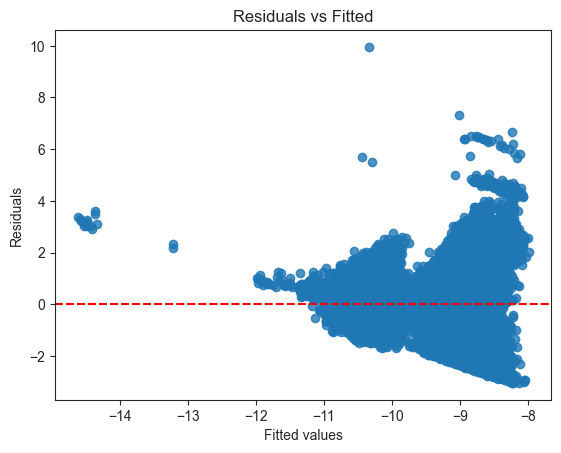

(np.float64(8602.176602368956), np.float64(0.0), np.float64(2826.8207988197223), np.float64(0.0))


In [25]:
# Design matrix
X = df_all[['Time_Budget_log',
       'Rho_log', 'Max_Depth_log', 'Nodes_log']]
X = sm.add_constant(X)  # Add intercept
y = df_all['Elapsed_Time_log']  # Dependent variable


# Regresión lineal
model = sm.OLS(y, X).fit()
print(model.summary())

residuals = model.resid
fitted_vals = model.fittedvalues

# Plot residuals vs fitted values
sns.residplot(x=fitted_vals, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs Fitted')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.show()

bp_test = het_breuschpagan(residuals, X)
print(bp_test)

In [26]:
ols_resid = model.resid
weights = 1 / (ols_resid ** 2 + 1e-6) 

model_wls = sm.WLS(y, X, weights=weights).fit()
print(model_wls.summary())

                            WLS Regression Results                            
Dep. Variable:       Elapsed_Time_log   R-squared:                       0.998
Model:                            WLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 3.671e+06
Date:                Mon, 13 Oct 2025   Prob (F-statistic):               0.00
Time:                        21:31:31   Log-Likelihood:                -46799.
No. Observations:               35941   AIC:                         9.361e+04
Df Residuals:                   35936   BIC:                         9.365e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -15.3189      0.002  -88

In [27]:
print("Intercept: ", f"{np.exp(model.params.iloc[0]):.2e}")

Intercept:  2.22e-07


## Table

In [28]:
data_folder = r'C:\Users\esteb\OneDrive - Universidad de los andes\Documentos\ANDES\Noveno Semestre\PA-RSPPs\PA-Experiments\output_new'
table = pd.read_csv(os.path.join(data_folder, 'table.csv'))
table['Time_Budget'] = table['Time_Budget'].round(2)
table['Elapsed_Time'] = table['Elapsed_Time'].apply(lambda x: '{:.2e}'.format(x))
parameter_columns = table.columns.drop('Elapsed_Time').tolist()
table = table.drop_duplicates(subset=parameter_columns, keep='first')

In [29]:
default_values = {
    "Time_Budget": 123.61,
    "Rho": 1.0,
    "Max_Depth": 2
}

df_time_budget = table[(table["Rho"] == default_values["Rho"]) &
                       (table["Max_Depth"] == default_values["Max_Depth"])]

df_rho = table[(table["Time_Budget"] == default_values["Time_Budget"]) &
               (table["Max_Depth"] == default_values["Max_Depth"])]

df_max_depth = table[(table["Time_Budget"] == default_values["Time_Budget"]) &
                     (table["Rho"] == default_values["Rho"])]


In [30]:
df_time_budget_SY = df_time_budget[df_time_budget["Network"] == "SY"][["Time_Budget", "Elapsed_Time"]]
df_time_budget_CR = df_time_budget[df_time_budget["Network"] == "CR"][["Time_Budget", "Elapsed_Time"]]
df_rho_SY = df_rho[df_rho["Network"] == "SY"][["Rho", "Elapsed_Time"]]
df_rho_CR = df_rho[df_rho["Network"] == "CR"][["Rho", "Elapsed_Time"]]
df_max_depth_SY = df_max_depth[df_max_depth["Network"] == "SY"][["Max_Depth", "Elapsed_Time"]]
df_max_depth_CR = df_max_depth[df_max_depth["Network"] == "CR"][["Max_Depth", "Elapsed_Time"]]


In [31]:
df_time_budget_CR.sort_values(by="Time_Budget", inplace=True)
df_time_budget_CR

,Time_Budget,Elapsed_Time
1,30.90,2.29e-05
4,61.80,2.19e-05
7,92.71,2.08e-05
10,123.61,5.62e-04
13,154.51,4.86e-03
16,185.41,3.90e-03
19,216.32,5.36e-03
22,247.22,6.68e-03


In [32]:
df_rho_CR.sort_values(by="Rho", inplace=True)
df_rho_CR

,Rho,Elapsed_Time
25,0.1,4.77e-04
28,0.2,3.91e-04
31,0.4,2.75e-04
34,0.5,2.81e-04
37,0.6,3.96e-04
40,0.7,4.50e-04
43,0.9,2.29e-04
10,1.0,5.62e-04


In [33]:
df_max_depth_CR.sort_values(by="Max_Depth", inplace=True)
df_max_depth_CR

,Max_Depth,Elapsed_Time
49,1,3.03e-04
10,2,5.62e-04
55,3,7.06e-04


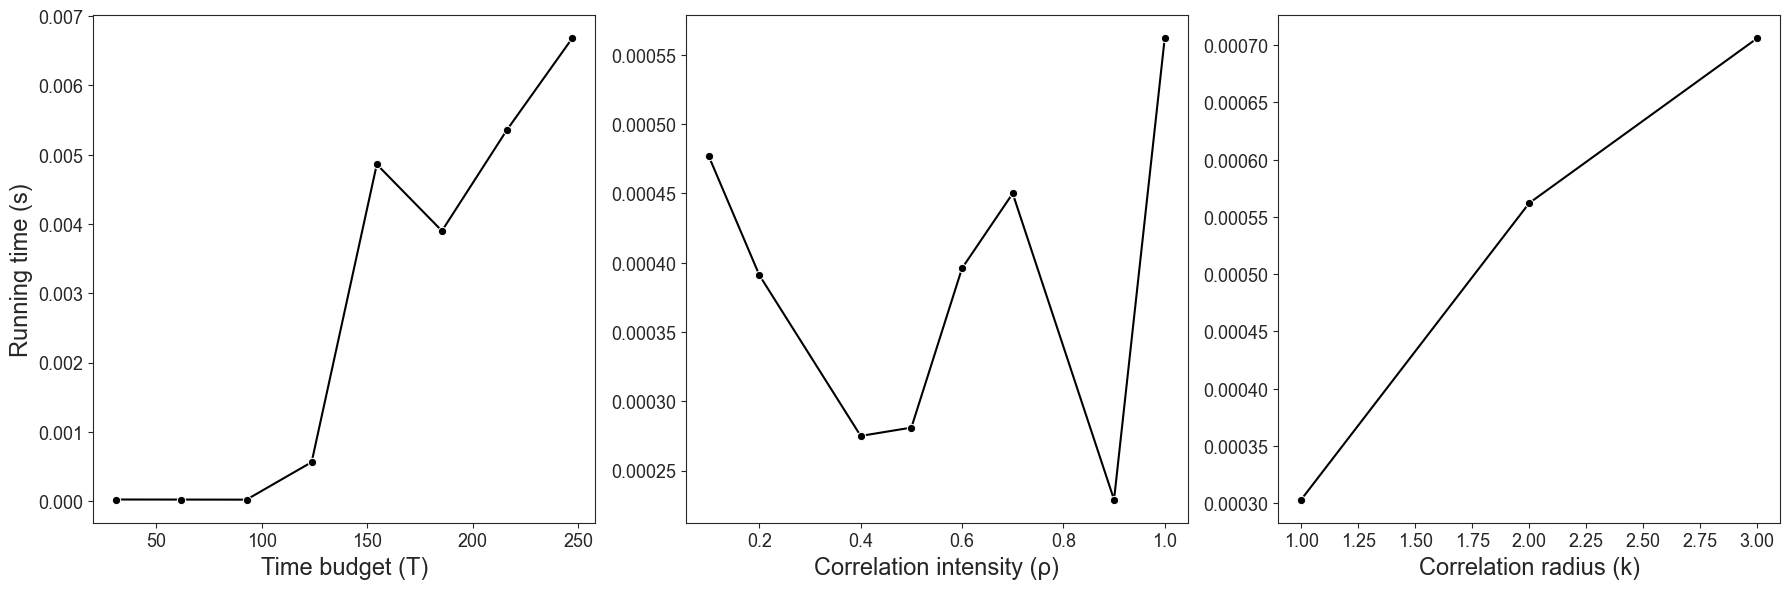

In [36]:
# Create subplots for parameter sensitivity analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
# define black color
black = "#000000"

# Time Budget plot - Chicago Regional only
df_time_budget_CR['Elapsed_Time'] = df_time_budget_CR['Elapsed_Time'].apply(lambda x: float(x))

sns.lineplot(data=df_time_budget_CR, x='Time_Budget', y='Elapsed_Time', 
             marker='o', ax=axes[0], color=black)
axes[0].set_xlabel('Time budget (T)', fontsize=17)
axes[0].set_ylabel('Running time (s)', fontsize=17)

#axes[0].set_title('Elapsed Time vs Time Budget', fontsize=16)
axes[0].tick_params(axis='both', which='major', labelsize=13)

# Rho plot - Chicago Regional only
df_rho_CR['Elapsed_Time'] = df_rho_CR['Elapsed_Time'].apply(lambda x: float(x))

sns.lineplot(data=df_rho_CR, x='Rho', y='Elapsed_Time', 
             marker='o', ax=axes[1], color=black)
axes[1].set_xlabel('Correlation intensity (ρ)', fontsize=17)
axes[1].set_ylabel('', fontsize=15)

#axes[1].set_title('Elapsed Time vs Rho', fontsize=16)
axes[1].tick_params(axis='both', which='major', labelsize=13)

# Max Depth plot - Chicago Regional only
df_max_depth_CR['Elapsed_Time'] = df_max_depth_CR['Elapsed_Time'].apply(lambda x: float(x))

sns.lineplot(data=df_max_depth_CR, x='Max_Depth', y='Elapsed_Time', 
             marker='o', ax=axes[2], color=black)
axes[2].set_xlabel('Correlation radius (k)', fontsize=17)
axes[2].set_ylabel('', fontsize=15)
#axes[2].set_title('Elapsed Time vs Max Depth', fontsize=16)
axes[2].tick_params(axis='both', which='major', labelsize=13)

plt.tight_layout()
plt.show()